In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 1. Read dataset
df = pd.read_csv("sales_data_sample.csv", encoding="latin1")
print(df.head())

   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbaye           NaN

In [2]:
# 2. Select numerical sales columns
X = df[["QUANTITYORDERED", "PRICEEACH", "SALES"]]

# Handle missing values
X = X.fillna(X.median())

# 3. Normalize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

c:\Users\jacks\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\jacks\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\jacks\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\jacks\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  

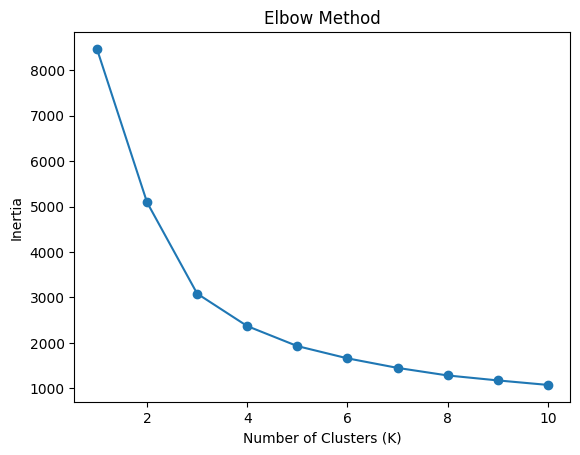

In [3]:
# 4. Elbow Method
inertia = []
for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertia.append(model.inertia_)

# Plot elbow curve
plt.plot(range(1, 11), inertia, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

In [4]:
# 5. Apply K-Means
k = 3  # Change according to the elbow plot
model = KMeans(n_clusters=k, random_state=42, n_init=10)
df["Cluster"] = model.fit_predict(X_scaled)

# Display results
print("\nSales data with clusters:")
print(df[[
    "QUANTITYORDERED", "PRICEEACH", "SALES", "Cluster"
]].head(10))

print("\nNumber of records in each cluster:")
print(df["Cluster"].value_counts().sort_index())


Sales data with clusters:
   QUANTITYORDERED  PRICEEACH    SALES  Cluster
0               30      95.70  2871.00        2
1               34      81.35  2765.90        2
2               41      94.74  3884.34        1
3               45      83.26  3746.70        1
4               49     100.00  5205.27        1
5               36      96.66  3479.76        2
6               29      86.13  2497.77        2
7               48     100.00  5512.32        1
8               22      98.57  2168.54        2
9               41     100.00  4708.44        1

Number of records in each cluster:
Cluster
0     881
1     907
2    1035
Name: count, dtype: int64
